<a href="https://colab.research.google.com/github/NadiyaNowshin/Image-Classification-with-Deep-Learning-and-CNNs/blob/main/image_classification_dense_vs_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Classification with Deep Learning and CNNs
**Dense network vs CNN on Fashion-MNIST**

I build two classifiers on Fashion-MNIST (28x28 grayscale clothing images, 10 classes): a fully-connected baseline and a CNN, then compare them.



## Part A: Data Preparation

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (60000, 28, 28), Test: (10000, 28, 28)


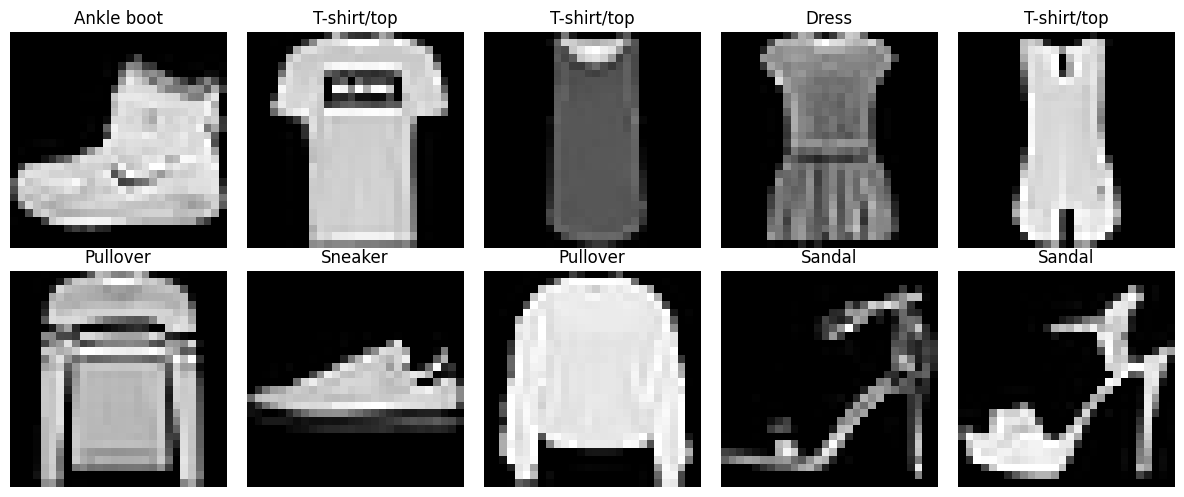

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import fashion_mnist
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

tf.random.set_seed(42)
np.random.seed(42)

(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print(f"Train: {X_train_full.shape}, Test: {X_test.shape}")

# 10 sample images with labels
plt.figure(figsize= (12,5))
for i in range(10):
  plt.subplot(2, 5 , i+1),
  plt.imshow(X_train_full[i], cmap="gray"),
  plt.title(class_names[y_train_full[i]]),
  plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Normalize pixel values to 0-1
X_train_full = X_train_full.astype("float32")/255.0
X_test = X_test.astype("float32")/255.0

# Train / validation split (55,000 / 5,000)
X_val , y_val = X_train_full[:5000] , y_train_full[:5000]
X_train , y_train = X_train_full[5000:] , y_train_full[5000:]

print(f"Train: {X_train.shape}, Val:{X_val.shape} , Test: {X_test.shape}")
print(f"Pixel range: {X_train.min()} - {X_train.max()}")

Train: (55000, 28, 28), Val:(5000, 28, 28) , Test: (10000, 28, 28)
Pixel range: 0.0 - 1.0


Pixels were divided by 255 so values lie in [0, 1], which helps gradient descent converge. The original 60,000 training images were split into 55,000 for training and 5,000 for validation. The 10,000 test images are untouched until final evaluation.

## Part B: Baseline Fully-Connected Network
Architecture: Flatten -> Dense(256, ReLU) -> Dense(128, ReLU) -> Dense(10, Softmax).

Loss: sparse categorical crossentropy (integer labels, 10 classes). Optimizer: Adam.

In [ ]:
dense_model = models.Sequential([
    layers.Input(shape = (28,28)),
    layers.Flatten(),
    layers.Dense(256, activation = "relu"), #parameter = 256 * 28*28 +256 = 200960
    layers.Dense(128, activation = "relu"), #parameter = 256 * 128 + 128 = 32896
    layers.Dense(10, activation = "softmax"), #parameter = 128 *10 +10 = 1290

], name = "dense_baseline")

dense_model.compile( optimizer = "adam",
                     loss = "sparse_categorical_crossentropy",
                     metrics = ["accuracy"])

dense_model.summary()

dense_history = dense_model.fit(X_train, y_train,
                                validation_data = (X_val, y_val),
                                epochs=15, batch_size=128, verbose = 1)


Model: "dense_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
430/430 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.8175 - loss: 0.5213 - val_accuracy: 0.8700 - val_loss: 0.3779
Epoch 2/15
430/430 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8651 - loss: 0.3736 - val_accuracy: 0.8784 - val_loss: 0.3337
Epoch 3/15
430/430 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8783 - loss: 0.3320 - val_accuracy: 0.8832 - val_loss: 0.3184
Epoch 4/15
430/430 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8871 - loss: 0.3066 - val_accuracy: 0.8846 - val_loss: 0.3139
Epoch 5/15
430/430 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8932 - loss: 0.2872 - val_accuracy: 0.8846 - val_loss: 0.3089
Epoch 6/15
430/430 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8991 - loss: 0.2711 - val_accuracy: 0.8884 - val_loss: 0.3074
Epoch 7/15
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9037 - loss: 0.2575 - val_accuracy: 0.8884 - val_loss: 0.3110
Epoch 8/15
430/430 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9084 - loss: 0.2447 - val_accuracy: 0.

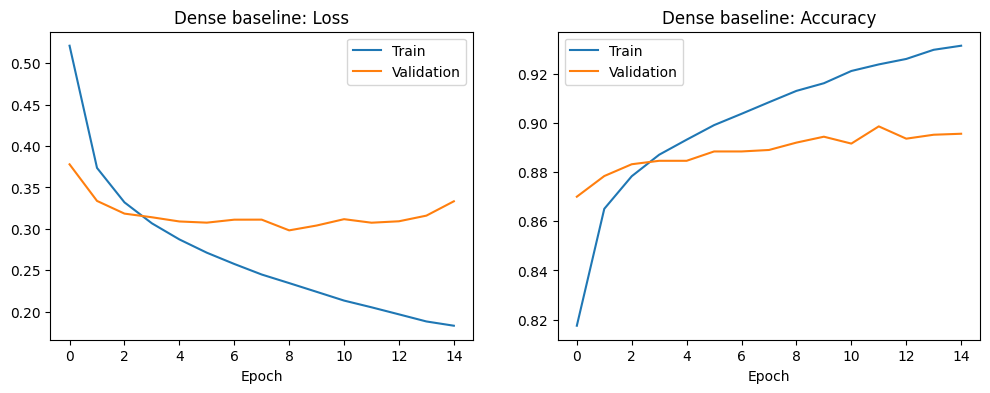

In [ ]:
def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.history["loss"], label="Train")
    ax[0].plot(history.history["val_loss"], label="Validation")
    ax[0].set_title(f"{title}: Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(history.history["accuracy"], label="Train")
    ax[1].plot(history.history["val_accuracy"], label="Validation")
    ax[1].set_title(f"{title}: Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.show()

plot_history(dense_history, "Dense baseline")

## Part C: CNN Model
Two Conv2D + MaxPooling blocks, each with Batch Normalization, followed by Dense layers with Dropout (0.5). Batch Normalization stabilizes training and Dropout reduces overfitting.

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 220,618 (861.79 KB)

 Trainable params: 220,426 (861.04 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_5
Received: inputs=('Tensor(shape=(None, 28, 28, 1))',)
  warnings.warn(msg)


430/430 - 16s - 38ms/step - accuracy: 0.7738 - loss: 0.6387 - val_accuracy: 0.7412 - val_loss: 0.7669
Epoch 2/15
430/430 - 2s - 6ms/step - accuracy: 0.8472 - loss: 0.4164 - val_accuracy: 0.8902 - val_loss: 0.3004
Epoch 3/15
430/430 - 2s - 5ms/step - accuracy: 0.8708 - loss: 0.3514 - val_accuracy: 0.9128 - val_loss: 0.2447
Epoch 4/15
430/430 - 2s - 6ms/step - accuracy: 0.8848 - loss: 0.3135 - val_accuracy: 0.9108 - val_loss: 0.2420
Epoch 5/15
430/430 - 3s - 6ms/step - accuracy: 0.8909 - loss: 0.2943 - val_accuracy: 0.9038 - val_loss: 0.2587
Epoch 6/15
430/430 - 3s - 6ms/step - accuracy: 0.8973 - loss: 0.2759 - val_accuracy: 0.9082 - val_loss: 0.2522
Epoch 7/15
430/430 - 2s - 6ms/step - accuracy: 0.9025 - loss: 0.2598 - val_accuracy: 0.9190 - val_loss: 0.2361
Epoch 8/15
430/430 - 2s - 6ms/step - accuracy: 0.9101 - loss: 0.2432 - val_accuracy: 0.8946 - val_loss: 0.2873
Epoch 9/15
430/430 - 2s - 6ms/step - accuracy: 0.9113 - loss: 0.2343 - val_accuracy: 0.9094 - val_loss: 0.2499
Epoch 10/1

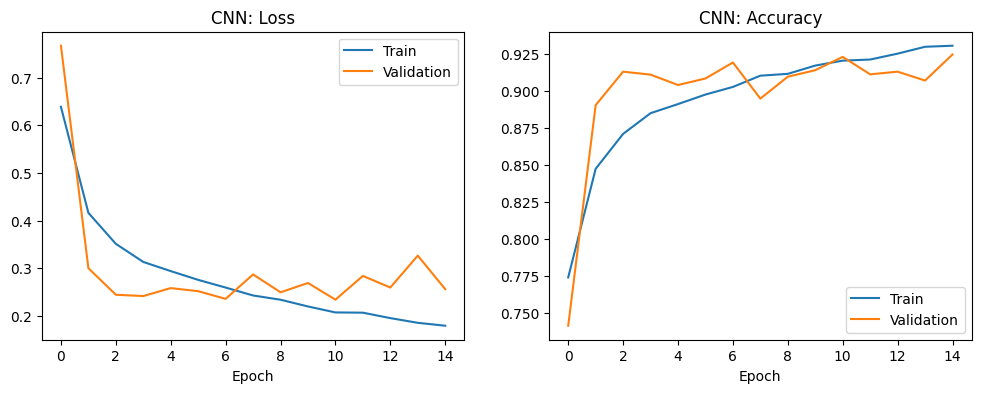

In [ ]:
# Add channel dimension for Conv2D
X_train_cnn = np.expand_dims(X_train, -1),
X_val_cnn = np.expand_dims(X_val, -1),
X_test_cnn = np.expand_dims(X_test, -1)

cnn_model = models.Sequential([
    layers.Input(shape = (28,28,1)),
    layers.Conv2D(32, 3, padding = "same", activation = "relu"), #parameter = 32*3*3+32= 320
    layers.BatchNormalization(), #parameter = 4*32 = 128
    layers.MaxPooling2D(), #shape = (None, 14, 14, 32)
    layers.Conv2D(64, 3, padding = "same", activation= "relu"), #parameter = 64*32*3*3+64= 18496
    layers.BatchNormalization(), #parameter = 4*64 = 256
    layers.MaxPooling2D(), #shape = (None, 7, 7, 64)
    layers.Flatten(), #shape = 7*7*64= 3136
    layers.Dense(64, activation= "relu"), #parameter = 3136*64+64= 320
    layers.Dropout(0.5),
    layers.Dense(10, activation = "softmax"), #parameter = 64*10+64= 650

], name = "CNN")

cnn_model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
cnn_model.summary()

cnn_history = cnn_model.fit(X_train_cnn, y_train,
                            validation_data=(X_val_cnn, y_val),
                            epochs=15, batch_size=128, verbose=2)

plot_history(cnn_history, "CNN")

## Part D: Evaluation and Comparison

In [ ]:
dense_loss, dense_acc = dense_model.evaluate(X_test, y_test, verbose=1)
cnn_loss, cnn_acc = cnn_model.evaluate(X_test, y_test, verbose=1)

def trainable_params(m):
  return int(np.sum([np.prod(w.shape) for w in m.trainable_weights]))

results = pd.DataFrame({
    "Model" : ["Dense baseline", "CNN"],
    "Test Accuracy": [f"{dense_acc:.4f}" , f"{cnn_acc:.4f}"],
    "Trainable parameters": [f"{trainable_params(dense_model):,}", f"{trainable_params(cnn_model):,}"],
})

results

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8788 - loss: 0.3752
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9165 - loss: 0.2693


,Model,Test Accuracy,Trainable parameters
0,Dense baseline,0.8788,"235,146"
1,CNN,0.9165,"220,426"


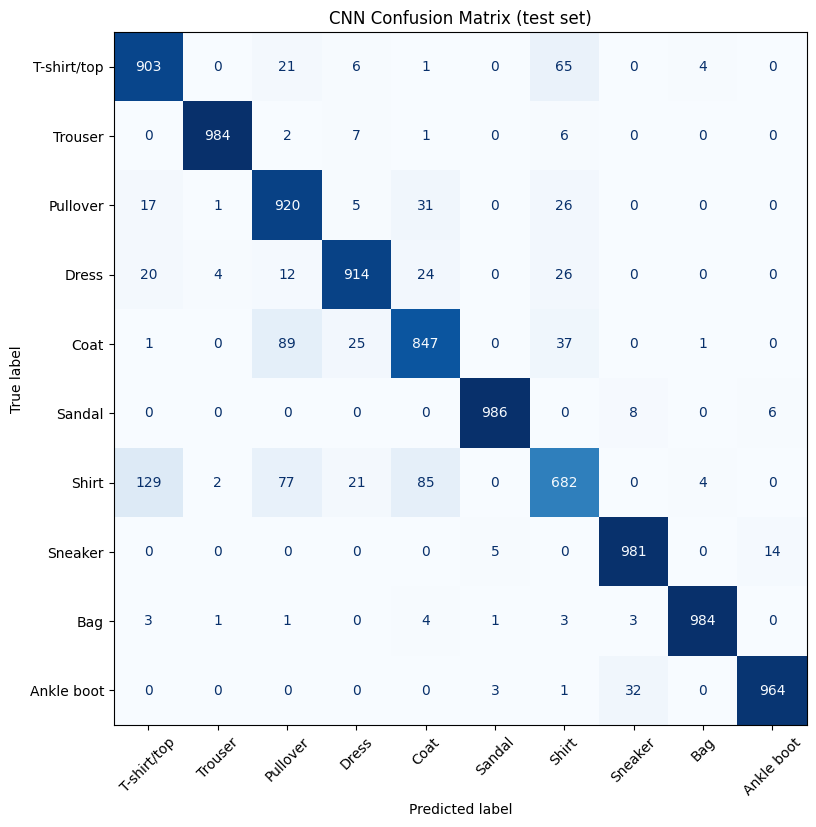

In [ ]:
cnn_probs = cnn_model.predict(X_test_cnn, verbose=0)
cnn_preds = np.argmax(cnn_probs, axis=1)

cm = confusion_matrix(y_test, cnn_preds)
fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("CNN Confusion Matrix (test set)")
plt.show()

835 misclassified out of 10000


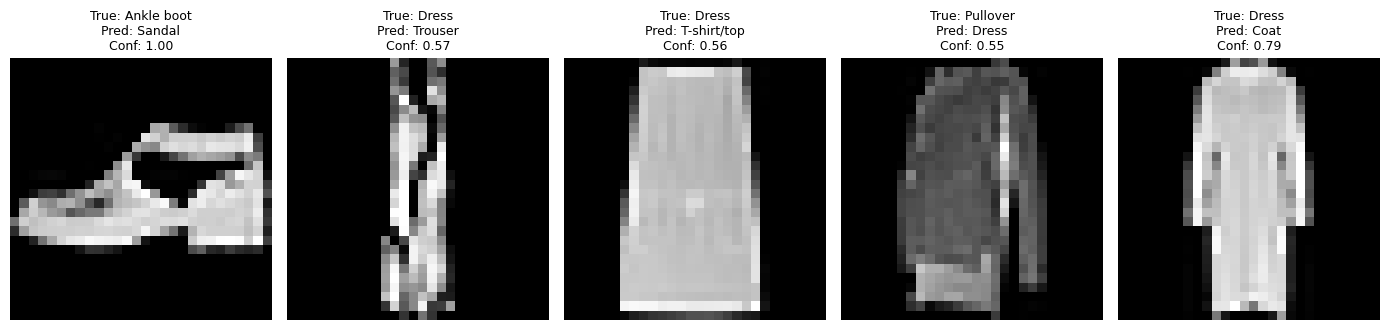

In [ ]:
wrong = np.where(cnn_preds != y_test)[0]
print(f"{len(wrong)} misclassified out of {len(y_test)}")

plt.figure(figsize=(14, 3.5))
for i, idx in enumerate(wrong[:5]):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[idx], cmap="gray")
    plt.title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[cnn_preds[idx]]}\n"
              f"Conf: {cnn_probs[idx].max():.2f}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

### Why the CNN failed on these images

1. image 3 - **True: Shirt, Pred: T-shirt/top.** These classes share almost the same silhouette at 28x28 resolution; the buttons and collar that distinguish a shirt are only a few pixels wide.
2. image 4 - **True: Coat, Pred: Shirt.** Both have long sleeves and a similar outline, and the low resolution removes texture and zipper details.
3. image - **True: Dress, Pred: T-Shirt.** Unusual shape or poor contrast also very light.

In [ ]:
h = dense_history.history

print("Final train accuracy:", round(h["accuracy"][-1] * 100, 2), "%")
print("Final val accuracy:  ", round(h["val_accuracy"][-1] * 100, 2), "%")
print("Best val accuracy:   ", round(max(h["val_accuracy"]) * 100, 2), "%",
      "at epoch", int(np.argmax(h["val_accuracy"])) + 1)
print("Lowest val loss at epoch:", int(np.argmin(h["val_loss"])) + 1)

Final train accuracy: 93.14 %
Final val accuracy:   89.56 %
Best val accuracy:    89.86 % at epoch 12
Lowest val loss at epoch: 9


## Part E: Reflection

**Why does the CNN outperform the dense network, even with fewer parameters?**
The dense network flattens each image into a 784-long vector, which destroys the 2D structure: neighbouring pixels are treated no differently from distant ones, and every pixel connects to every neuron. The CNN keeps the spatial layout and uses small shared filters that slide across the image. Weight sharing means the same edge or texture detector is reused at every location, so the network needs far fewer parameters (235,146 vs 220,618) while learning features that are translation-invariant. Stacked convolutional layers build a hierarchy, from edges to textures to parts of garments, and pooling adds tolerance to small shifts. The result was a test accuracy of 0.9163 compared with 0.8790 for the dense model.

**What did I observe about overfitting?**
The dense baseline showed a growing gap between training and validation performance: training accuracy kept rising to about 93.14% while validation accuracy plateaued near 89.56% and validation loss began to increase after around epoch 9. This indicates it was memorising training images rather than learning general features. The CNN overfitted less because of weight sharing, Batch Normalization and Dropout, and its validation curve followed the training curve more closely, though a small gap remained.

**What would I try next?**
First, add data augmentation (small rotations, zoom, horizontal flips), which gives the model more varied examples. Second, deepen the CNN with a third convolutional block, tune the learning rate with a scheduler, and use early stopping to stop at the best validation epoch. Third, try transfer learning with a pretrained network such as MobileNetV2, which requires resizing the images. Finally, higher-resolution inputs or targeted augmentation for those classes could help the most.